# Volatility forecasting study: evidence walkthrough

Reads the saved JSON results in `results/`. It needs no broker data.

Core construction, per instrument on M5 bars:

$$\mathrm{ATR}^{(14)}_t = \tfrac{13}{14}\,\mathrm{ATR}^{(14)}_{t-1} + \tfrac{1}{14}\,(H_t - L_t), \qquad
S_\tau(t) = \mathrm{median}\{\mathrm{ATR}_{u} : \tau(u)=\tau(t),\ u \in \text{previous 60 sessions}\}$$

$$\mathrm{abn}_t = \frac{\mathrm{ATR}_t}{S_{\tau}(t)}, \qquad
\pi_t = \sum_{j=0}^{99}\mathbf 1[\mathrm{abn}_{t-j} \le \mathrm{abn}_t], \qquad
\text{compressed}_t \iff \pi_t < 20$$

$\tau(t)$ is the New York 5-minute slot, so `abn` measures how quiet the market is *for that time of day*.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "figures"))
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 140)

In [2]:
log = json.load(open(ROOT / "results" / "research_log.json"))
ents = pd.DataFrame(log["entries"])
print(f"{len(ents)} registered tests")
ents.groupby(["part", "prespecified"]).size().unstack(fill_value=0)

330 registered tests


prespecified,False,True
part,,
1,0,24
11/12,0,12
14,0,12
2,0,6
2/7,0,6
4,0,30
5,0,48
6,0,12
7,0,30


## 1. Multiple-testing control (Benjamini–Hochberg, q = 0.10)

Sort the $m$ p-values $p_{(1)}\le\dots\le p_{(m)}$, find $k^\ast=\max\{i: p_{(i)} \le q\,i/m\}$,
and reject the hypotheses ranked $1..k^\ast$. This is applied separately to the volatility and
directional families.

In [3]:
def bh(p, q=0.10):
    p = np.asarray(p); o = np.argsort(p); m = len(p)
    ok = p[o] <= q * np.arange(1, m + 1) / m
    k = (np.nonzero(ok)[0].max() + 1) if ok.any() else 0
    out = np.zeros(m, bool); out[o[:k]] = True
    return out

pre = ents[ents.prespecified & ents.p_value.notna()]
fam = {"volatility": pre[pre.part.isin(["5", "11/12", "4", "6", "2"])],
       "directional": pre[pre.part.isin(["7", "8/9/10"])]}
pd.DataFrame({k: {"tests": len(v), "raw p<0.05": int((v.p_value < 0.05).sum()),
                  "expected by chance": 0.05 * len(v), "survive BH": int(bh(v.p_value).sum())}
              for k, v in fam.items()}).T

,tests,raw p<0.05,expected by chance,survive BH
volatility,102.0000,66.0000,5.1000,67.0000
directional,132.0000,9.0000,6.6000,0.0000


## 2. Regime persistence vs a first-order Markov chain

If states were Markov, $P(\text{same state at } t+k) = (P^k)_{ss}$ for the one-step transition matrix $P$.
The excess of observed persistence over that prediction is the memory a Markov model misses.

In [4]:
r1 = json.load(open(ROOT / "results" / "r1_persistence.json"))
rows = []
for sym, d in r1.items():
    for k, v in d["adj"]["k"].items():
        c = v["per_state"]["compressed"]
        rows.append(dict(symbol=sym, k=int(k), observed=c["P_same"], markov=c["markov_k_step"],
                         excess=c["excess_vs_markov"], unconditional=c["unconditional"]))
pd.DataFrame(rows).pivot(index="k", columns="symbol", values="excess")

symbol,EURUSD,GER40.cash,US100.cash,US30.cash,US500.cash,XAUUSD
k,,,,,,
1,0.0004,0.0013,0.0012,0.0011,0.0012,0.0012
3,0.0803,0.0727,0.0721,0.0736,0.0710,0.0730
6,0.1512,0.1405,0.1405,0.1422,0.1384,0.1394
12,0.1760,0.1724,0.1715,0.1743,0.1731,0.1640
24,0.0915,0.1081,0.1080,0.1060,0.1128,0.0860
48,-0.0132,-0.0037,-0.0064,-0.0124,-0.0034,-0.0186


## 3. Session-handover forecast (the strongest result)

Quiet run-in = bottom quintile of pre-boundary `abn`. Outcome = a clock-referenced spike in the
next 2 hours. The confidence interval comes from a **day-block bootstrap**: whole sessions are
resampled, so intraday autocorrelation cannot narrow it.

In [5]:
r4 = json.load(open(ROOT / "results" / "r4_sessions.json"))
tab = pd.DataFrame({(s, b): {"P(spike) quiet": v["P_spike_quiet"], "P(spike) rest": v["P_spike_rest"],
                             "diff": v["spike_diff"]["diff"], "ci_lo": v["spike_diff"]["ci_lo"],
                             "ci_hi": v["spike_diff"]["ci_hi"]}
                    for s, d in r4.items() for b, v in d.items()}).T
print(f"cells with CI entirely below zero: {(tab.ci_hi < 0).sum()} / {len(tab)}")
tab

cells with CI entirely below zero: 24 / 24


P(spike) quiet  P(spike) rest    diff   ci_lo   ci_hi
XAUUSD     asia_to_london          0.1853         0.6537 -0.4684 -0.5309 -0.4069
           london_to_ny            0.6293         0.8576 -0.2283 -0.2941 -0.1636
           ny_cash_open            0.3966         0.7087 -0.3122 -0.3801 -0.2432
           ny_am_to_pm             0.0957         0.3732 -0.2776 -0.3265 -0.2276
EURUSD     asia_to_london          0.3691         0.7221 -0.3530 -0.4227 -0.2854
           london_to_ny            0.5408         0.6896 -0.1488 -0.2186 -0.0780
           ny_cash_open            0.3348         0.6223 -0.2876 -0.3541 -0.2199
           ny_am_to_pm             0.0730         0.2961 -0.2232 -0.2661 -0.1803
US100.cash asia_to_london          0.2931         0.8050 -0.5119 -0.5754 -0.4494
           london_to_ny            0.8052         0.9513 -0.1461 -0.2002 -0.0931
           ny_cash_open            0.7414         0.9675 -0.2262 -0.2834 -0.1712
           ny_am_to_pm             0.1473         0.4002 -0.2529 -0.3110 -0.1948
US500.cash asia_to_london          0.2543         0.8037 -0.5494 -0.6075 -0.4879
           london_to_ny            0.6710         0.9188 -0.2478 -0.3074 -0.1840
           ny_cash_open            0.5647         0.9199 -0.3553 -0.4211 -0.2895
           ny_am_to_pm             0.1518         0.4821 -0.3303 -0.3852 -0.2732
US30.cash  asia_to_london          0.3017         0.8220 -0.5203 -0.5839 -0.4567
           london_to_ny            0.8268         0.9545 -0.1277 -0.1786 -0.0790
           ny_cash_open            0.7500         0.9729 -0.2229 -0.2812 -0.1701
           ny_am_to_pm             0.1562         0.4451 -0.2888 -0.3492 -0.2329
GER40.cash asia_to_london          0.6681         0.9508 -0.2826 -0.3481 -0.2226
           london_to_ny            0.3712         0.6900 -0.3189 -0.3844 -0.2490
           ny_cash_open            0.3231         0.6696 -0.3464 -0.4131 -0.2765
           ny_am_to_pm             0.1096         0.4007 -0.2910 -0.3415 -0.2384

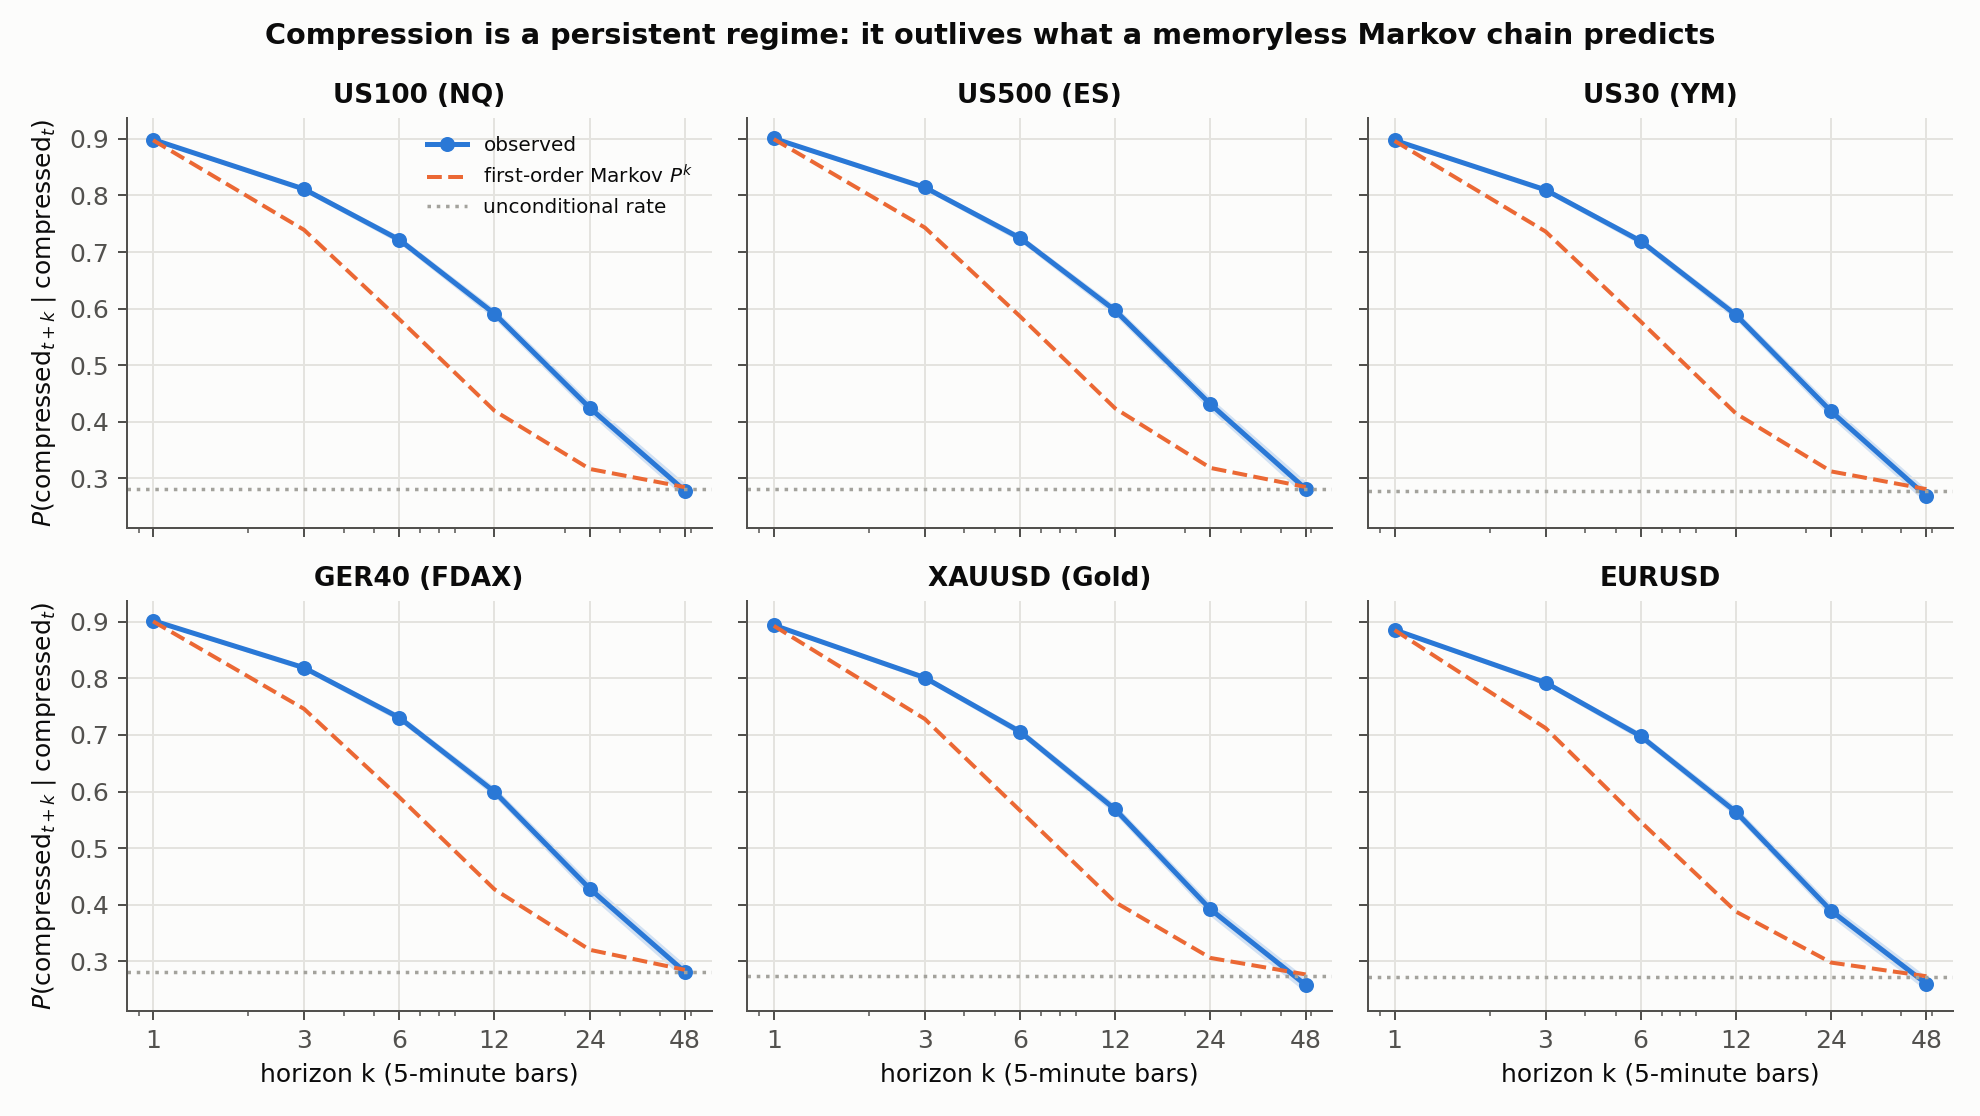

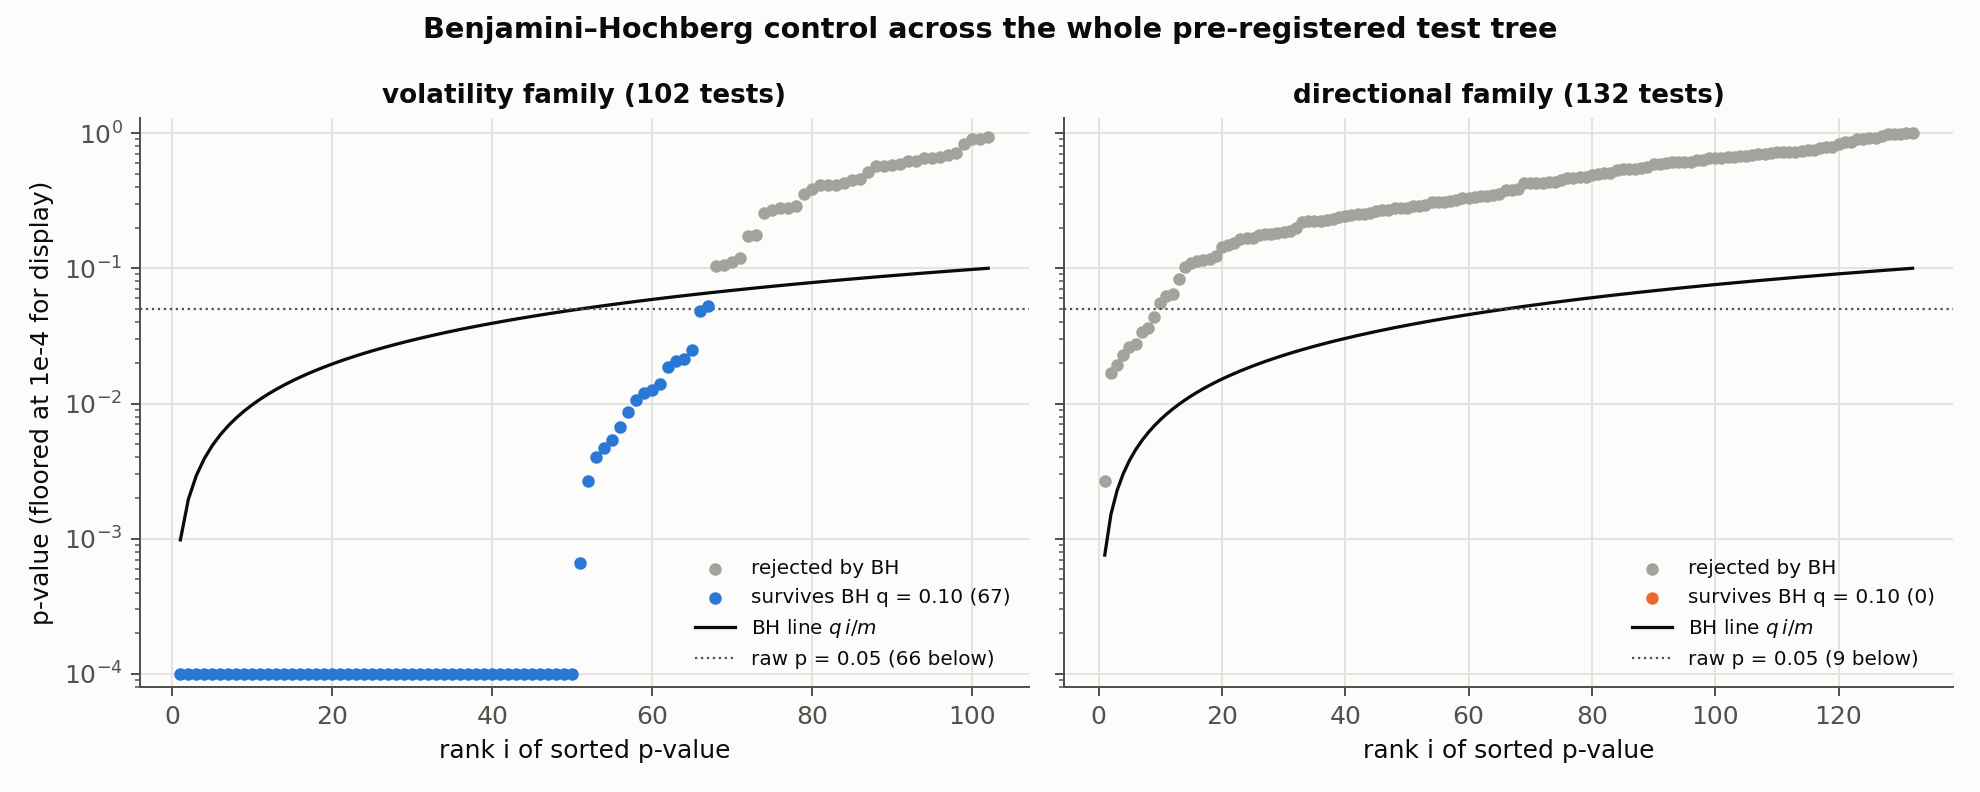

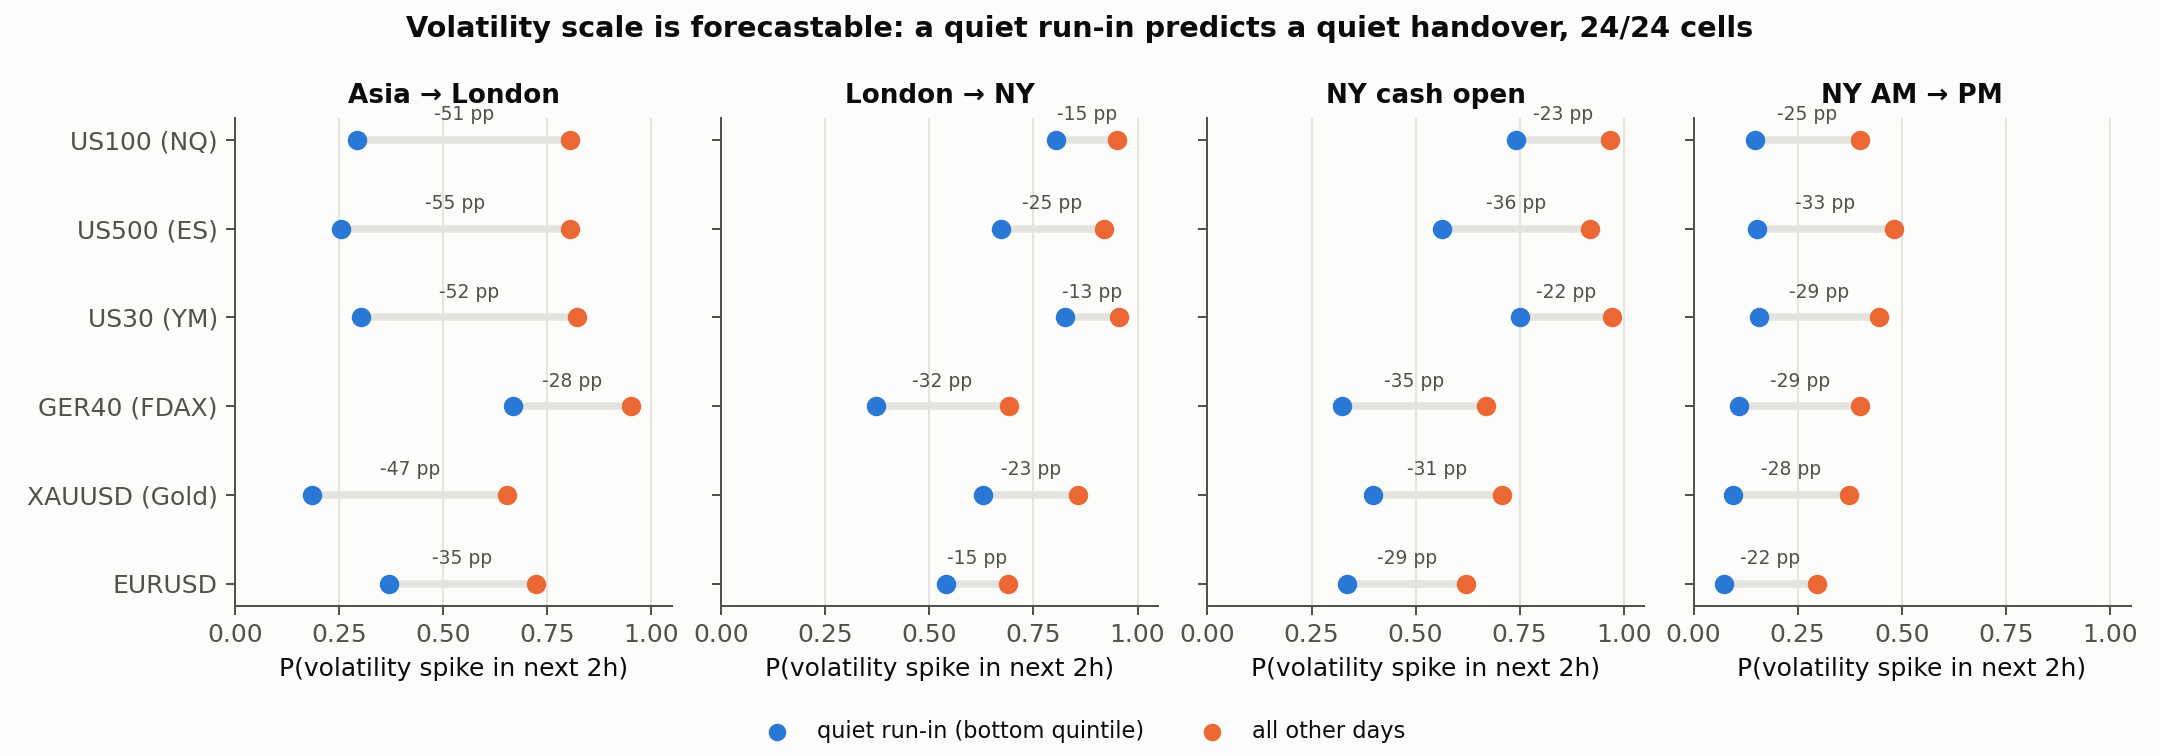

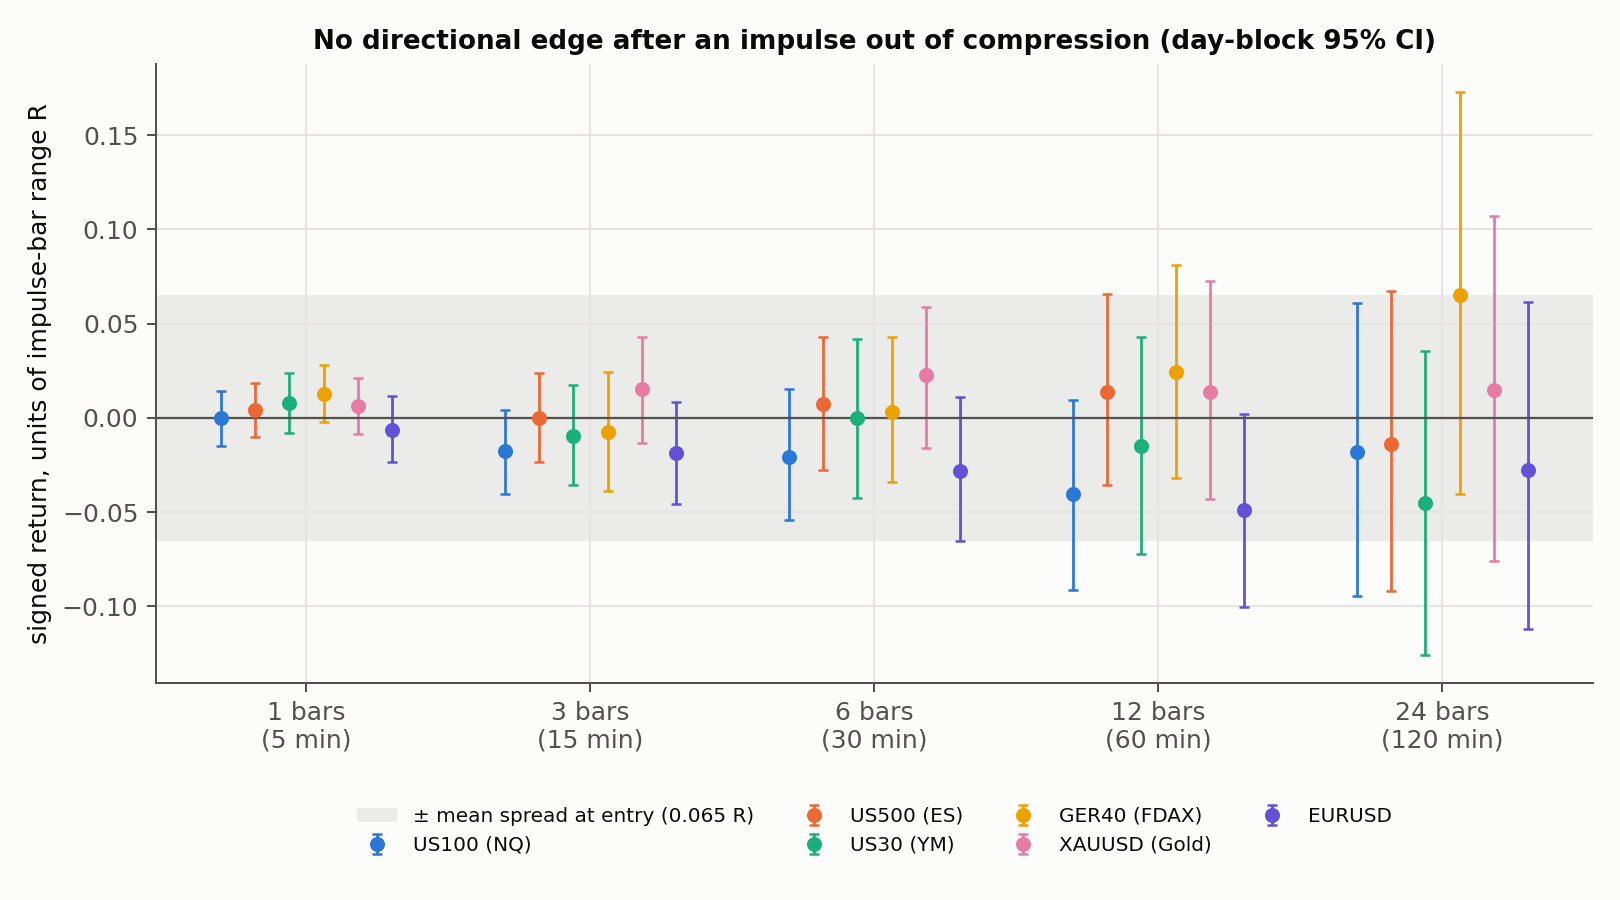

In [6]:
import make_figures as mf
mf.fig_persistence(); mf.fig_fdr(); mf.fig_sessions(); mf.fig_directional()
for f in ["fig1_regime_persistence", "fig2_fdr_by_family", "fig3_session_handover_forecast", "fig4_directional_null"]:
    display(Image(filename=str(ROOT / "figures" / f"{f}.png"), width=860))